# LAB 2 for CS4243: Perspective-Aware Virtual Advertisement Overlay
## Notebook 3 — Occlusion handling and compositing
> **Introduction.** This notebook develops **Stage 3 (Composite)** in `overlaylab/compositing.py`. Hysteresis thresholds
> and the minimum component area are chosen on the three **validation** masks of the common clip only
> (`select_difference_thresholds`), frozen, and reported on the three **test** masks of the common clip, on the mask
> frames of the combined and viewpoint clips (section 6) and later on your personal audit masks. The cells marked
> **REQUIRED** must be completed.

## 1. Imports, validation masks, and predicted homographies
Run Notebook 2 first, after A has finalised the Stage 1/2 configuration. This notebook requires its
`outputs/thresholds.json`; it does not silently substitute default localisation/tracking settings.
File existence alone does not establish that A has validated those choices. [AI-LANGUAGE]

Only the three common validation masks are loaded before Stage 3 selection. Test masks are loaded in section 4,
after freezing. Homographies come from `localise_board` alone; no common-clip ground-truth corners are used to
initialise or correct predictions. A failed validation localisation stops selection instead of dropping a hard frame.
The mask experiments use independent single-frame localisation at notebook resolution, not a temporal tracker;
final full-resolution video/stress-table metrics must be generated separately. [AI-DESIGN]

In [1]:
# [AI-CODE] Load A's frozen settings and prepare validation-only inputs.
import sys
import json
from copy import deepcopy
from dataclasses import asdict
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
ROOT = ROOT.resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
import cv2

from overlaylab import data, metrics, visualize as viz
from overlaylab import supplied as sp
from overlaylab.config import PipelineConfig, replace
from overlaylab.localisation import localise_board, artwork_to_frame
from overlaylab.compositing import (
    hysteresis, compensated_difference, occlusion_mask, select_difference_thresholds, composite,
)
from overlaylab.geometry import warp_artwork

threshold_path = ROOT / "outputs" / "thresholds.json"
if not threshold_path.exists():
    raise FileNotFoundError("Finish Notebook 2 and freeze Stage 1/2 in outputs/thresholds.json first.")
upstream_document = json.loads(threshold_path.read_text(encoding="utf-8"))
if not all(isinstance(upstream_document.get(k), dict) and upstream_document[k]
           for k in ("localisation", "track")):
    raise ValueError("thresholds.json must contain A's localisation and track settings.")
# Preserve all incoming fields exactly; section 3 changes only the occlusion block.
upstream_only = {k: deepcopy(v) for k, v in upstream_document.items() if k != "occlusion"}
config = PipelineConfig.from_json(json.dumps(upstream_document))
info = sp.video_info(data.COMMON_CLIP)
width = data.NOTEBOOK_WIDTH
factor = width / info["width"]
config.resize_width = width
reference_full = data.load_reference()
reference = sp.resize_width(reference_full, max(8, int(round(reference_full.shape[1] * factor))))
config.localisation.warp.reference_shape = reference.shape[:2]
artwork = data.load_artwork("ad")

EVIDENCE = ROOT / "student_files" / "notebook3"
EVIDENCE.mkdir(parents=True, exist_ok=True)
search_path = EVIDENCE / "validation_search.json"
seed_occlusion_full = asdict(config.occlusion)
# On a fresh-kernel rerun, reproduce the ORIGINAL grid, not a new grid centred
# on the previously selected thresholds. Reuse only a matching prior handoff.
if search_path.exists():
    previous = json.loads(search_path.read_text(encoding="utf-8"))
    if (previous.get("upstream") == upstream_only
            and previous.get("processing_width") == width
            and previous.get("frozen_occlusion_full") == upstream_document.get("occlusion")):
        seed_occlusion_full = previous["input_occlusion_full"]
        print("Reusing the original validation-search grid from the previous run.")
config.occlusion = PipelineConfig.from_json(json.dumps({"occlusion": seed_occlusion_full})).occlusion
config.occlusion.min_area = max(1, int(round(config.occlusion.min_area * factor ** 2)))
if config.occlusion.mode != "difference":
    raise ValueError("Notebook 3 requires the motion-compensated difference mode.")

masks_val = data.load_gt_masks("validation", width=width)
assert len(masks_val) == 3, "Expected three common-clip validation masks."

def read_mask_frames(indices):
    wanted = set(indices)
    return {i: frame for i, frame in sp.iter_video(
        data.COMMON_CLIP, step=1, width=width, start=min(wanted), stop=max(wanted) + 1)
        if i in wanted}

mask_frames = read_mask_frames(masks_val)
homs, localisation_diagnostics = {}, {}
for frame_id in sorted(masks_val):
    if frame_id not in mask_frames:
        raise FileNotFoundError(f"Missing validation frame {frame_id}; do not skip validation targets.")
    H, _, _, _, diag = localise_board(reference, mask_frames[frame_id], config.localisation)
    homs[frame_id] = H if H is not None and diag["status"] else None
    localisation_diagnostics[frame_id] = diag
failed = [i for i in masks_val if homs[i] is None]
assert not failed, f"Validation localisation failed on {failed}; investigate Stage 1 on validation before selection."
print("common_clip | validation | independent | processing width:", width,
      "| frames:", sorted(masks_val), "| scale:", factor)

METRIC_KEYS = ("iou", "f1", "boundary_f1", "leakage")

def finite_mean(values):
    values = np.asarray(list(values), dtype=float)
    valid = np.isfinite(values)
    return (float(values[valid].mean()) if valid.any() else float("nan"), int(valid.sum()))

def fmt(value):
    return f"{value:.4f}" if np.isfinite(value) else "n/a"

def evaluate_mask_frame(frame_id, truth, subset):
    frame, H = mask_frames[frame_id], homs[frame_id]
    m, dmap, components = occlusion_mask(frame, H, reference, config.occlusion)
    Ha = artwork_to_frame(artwork, H, config.localisation)
    warped, coverage = warp_artwork(artwork, Ha, frame.shape)
    out, alpha = composite(frame, warped, coverage, m, config.composite)
    baseline_mask = np.zeros_like(m)
    baseline, baseline_alpha = composite(frame, warped, coverage, baseline_mask, config.composite)
    row = {"clip": "common_clip", "subset": subset, "variant": "independent",
           "frame": int(frame_id), "status": "scored", "processing_width": width,
           "iou": metrics.mask_iou(m, truth), "f1": metrics.mask_f1(m, truth),
           "boundary_f1": metrics.boundary_f1(m, truth), "leakage": metrics.leakage(alpha, truth),
           "baseline_iou": metrics.mask_iou(baseline_mask, truth),
           "baseline_f1": metrics.mask_f1(baseline_mask, truth),
           "baseline_boundary_f1": metrics.boundary_f1(baseline_mask, truth),
           "baseline_leakage": metrics.leakage(baseline_alpha, truth),
           "components": int(len(components)), "mask_pixels": int(m.sum())}
    panels = [viz.label(frame, "original"), viz.label(viz.heatmap(dmap, 0.6), "difference"),
              viz.label(viz.overlay_mask(frame, truth), "ground-truth occlusion"),
              viz.label(viz.overlay_mask(frame, m), "predicted occlusion"),
              viz.label(baseline, "without occlusion handling"), viz.label(out, "with occlusion handling"),
              viz.label(viz.heatmap(alpha, 1), "alpha"),
              viz.label(viz.overlay_mask(frame, truth & ~m), "missed foreground"),
              viz.label(viz.overlay_mask(frame, m & ~truth), "false foreground")]
    fig = plt.figure(figsize=(16, 9))
    plt.imshow(viz.montage(panels, cols=3))
    plt.axis("off")
    plt.title(f"common_clip | {subset} | independent | frame {frame_id} | width {width}")
    plt.tight_layout()
    fig.savefig(EVIDENCE / f"common_clip_{subset}_independent_frame_{frame_id:06d}.png", dpi=130)
    plt.show()
    return row

def summarise_rows(rows, expected):
    summary = {"expected": expected,
               "scored": sum(r["status"] == "scored" for r in rows),
               "hidden": sum(r["status"] == "hidden" for r in rows),
               "missing": sum(r["status"] == "missing" for r in rows)}
    scored_rows = [r for r in rows if r["status"] == "scored"]
    for key in (*METRIC_KEYS, *("baseline_" + k for k in METRIC_KEYS)):
        mean, count = finite_mean(r[key] for r in scored_rows)
        summary[key] = {"mean": mean, "n_scored": count}
    return summary

Reusing the original validation-search grid from the previous run.
common_clip | validation | independent | processing width: 640 | frames: [96, 192, 272] | scale: 0.5


## 2. The motion-compensated difference
Warp the reference into the frame, fit a global gain and offset on the best-agreeing pixels, and look at the difference
map. Illumination change alone should *not* light up; the card crossing the poster should.

frame 96: fitted gain 0.961, offset 0.002


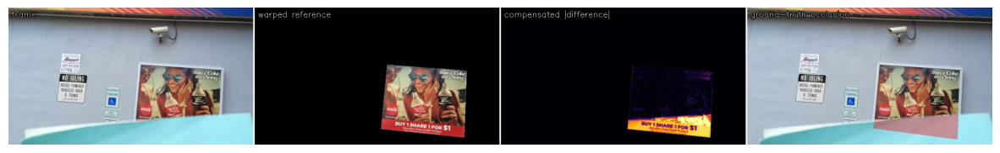

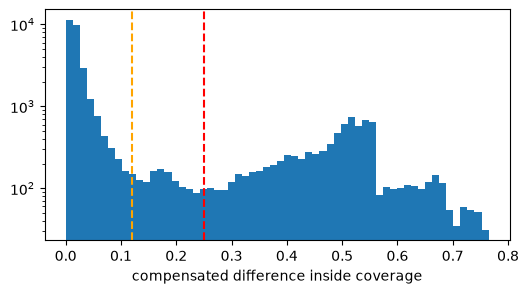

In [2]:
i = sorted(masks_val)[0]
warped_ref, cov = warp_artwork(reference, homs[i], mask_frames[i].shape)
diff, (gain, offset) = compensated_difference(mask_frames[i], warped_ref, cov, config.occlusion)
print(f"frame {i}: fitted gain {gain:.3f}, offset {offset:.3f}")
plt.figure(figsize=(15, 4)); plt.imshow(viz.montage([viz.label(mask_frames[i], "frame"), viz.label(warped_ref, "warped reference"), viz.label(viz.heatmap(diff, 0.6), "compensated |difference|"), viz.label(viz.overlay_mask(mask_frames[i], masks_val[i]), "ground-truth occlusion")], cols=4)); plt.axis("off"); plt.show()
plt.figure(figsize=(6, 3)); plt.hist(diff[cov], bins=60, log=True); plt.axvline(config.occlusion.weak, color="orange", ls="--"); plt.axvline(config.occlusion.strong, color="red", ls="--"); plt.xlabel("compensated difference inside coverage"); plt.show()

## 3. Select the thresholds on the validation masks (REQUIRED)
Search strong / weak / minimum-area settings using **only the three validation masks**.
The grid is centred on the incoming occlusion config. Among maximum-IoU settings choose strong nearest the
midpoint of the tied strong range; resolve remaining ties by closeness to the input weak/min_area, then smaller
values. Undefined IoUs remain NaN and are excluded from means with their denominator recorded. [AI-CODE]

The selected minimum area is measured at notebook resolution and converted back to full-resolution pixel area
with `1 / factor**2` for `outputs/thresholds.json`. All other incoming blocks, especially localisation and tracking,
remain unchanged. The search log, input config and selected config are saved to `student_files/notebook3/` so a
fresh-kernel rerun can reproduce the same original grid. Run this section before inspecting test or stress results;
do not retune from those results. [AI-DESIGN]

common_clip | validation | independent | top 10 grid settings:
{'strong': 0.15, 'weak': 0.12, 'min_area': 19, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
{'strong': 0.15, 'weak': 0.12, 'min_area': 38, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
{'strong': 0.15, 'weak': 0.12, 'min_area': 76, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
{'strong': 0.2, 'weak': 0.12, 'min_area': 19, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
{'strong': 0.2, 'weak': 0.12, 'min_area': 38, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
{'strong': 0.2, 'weak': 0.12, 'min_area': 76, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
{'strong': 0.25, 'weak': 0.12, 'min_area': 19, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
{'strong': 0.25, 'weak': 0.12, 'min_area': 38, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
{'strong': 0.25, 'weak': 0.12, 'min_area': 76, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
{'strong': 0.3, 'weak': 0.12, 'min_area': 19, 'mean_iou': 0.8971183445410912, 'n_scored': 3}
S

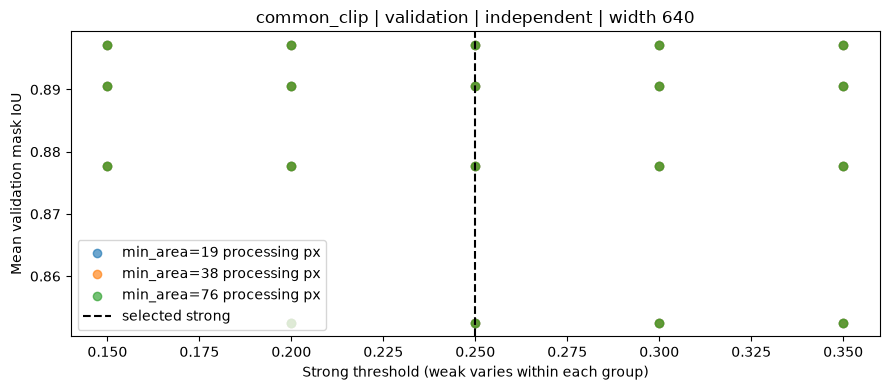

Saved Stage 3 thresholds; Stage 1/2 and all other blocks preserved.
Full-resolution occlusion settings: {'mode': 'difference', 'strong': 0.25, 'weak': 0.12, 'min_area': 152, 'open_radius': 2, 'connectivity': 8, 'gain_quantile': 0.5, 'feather': 3}


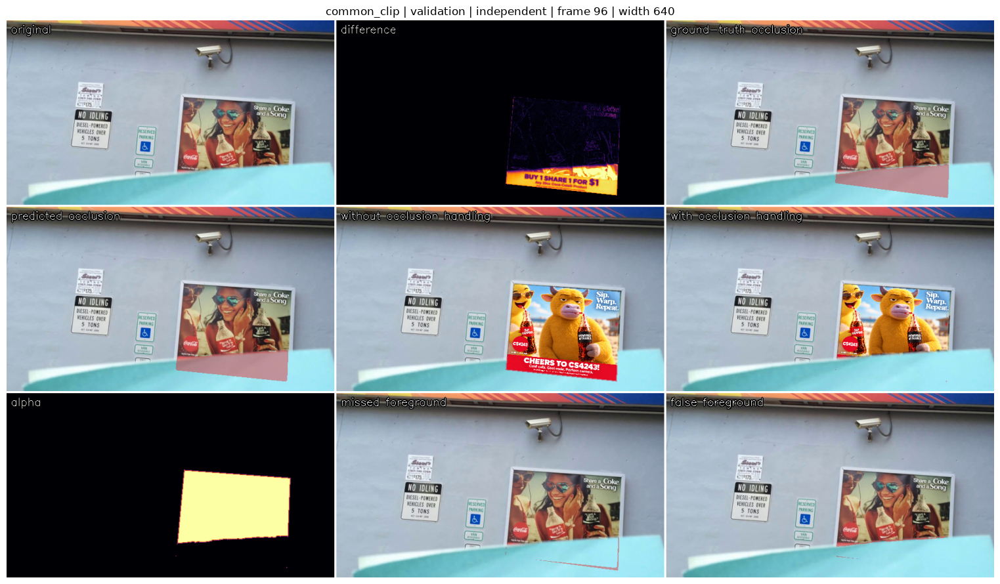

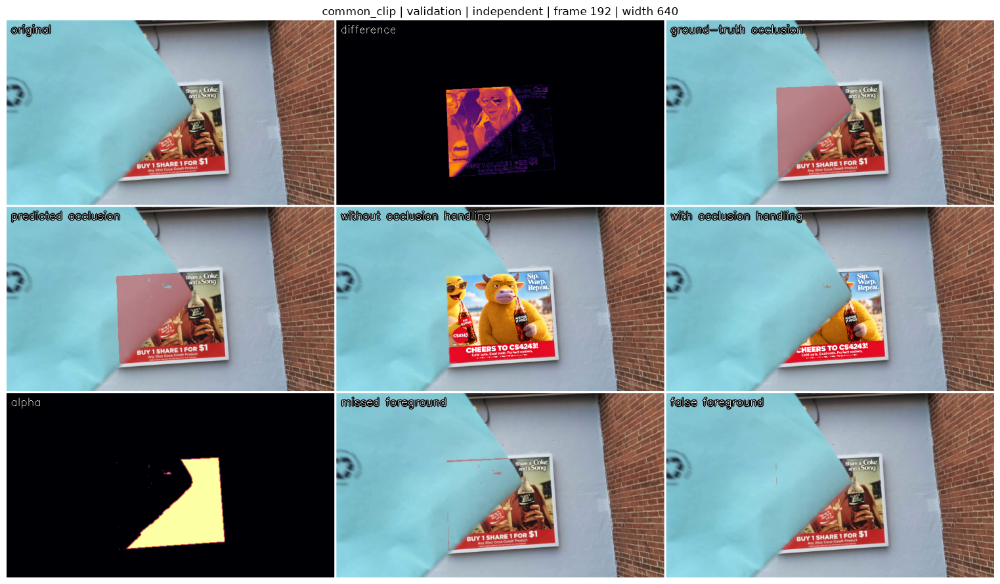

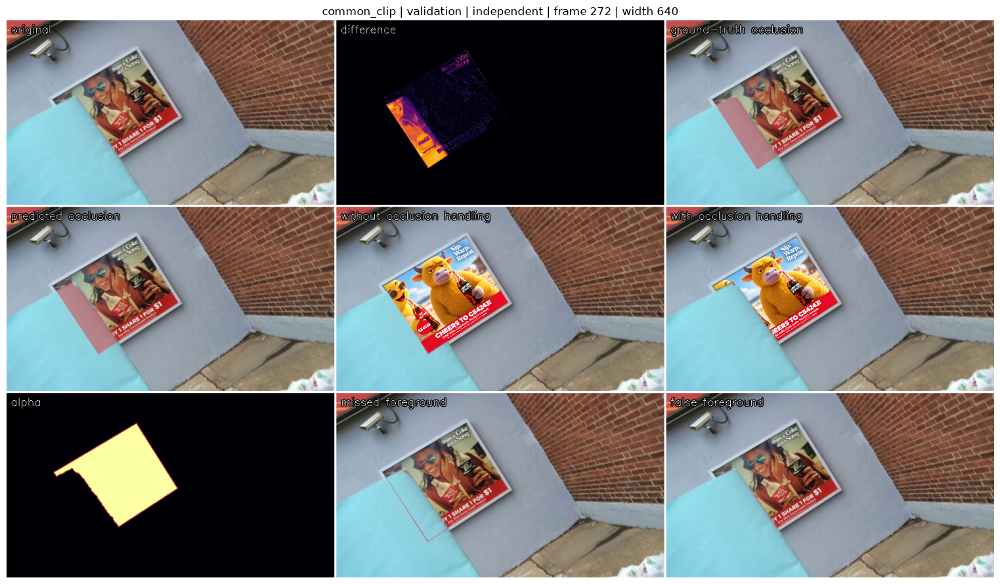

{
  "expected": 3,
  "scored": 3,
  "hidden": 0,
  "missing": 0,
  "iou": {
    "mean": 0.8971183445410912,
    "n_scored": 3
  },
  "f1": {
    "mean": 0.9456141754239434,
    "n_scored": 3
  },
  "boundary_f1": {
    "mean": 0.6940588576980217,
    "n_scored": 3
  },
  "leakage": {
    "mean": 0.013626402560925432,
    "n_scored": 3
  },
  "baseline_iou": {
    "mean": 0.0,
    "n_scored": 3
  },
  "baseline_f1": {
    "mean": 0.0,
    "n_scored": 3
  },
  "baseline_boundary_f1": {
    "mean": 0.0,
    "n_scored": 3
  },
  "baseline_leakage": {
    "mean": 0.9262584901539568,
    "n_scored": 3
  }
}


In [3]:
# [AI-CODE] Validation-only search, evidence, and the Stage 3 handoff.
val_ids = sorted(masks_val)
val_inputs = [(mask_frames[i], homs[i], reference) for i in val_ids]
frozen_occ, search_log = select_difference_thresholds(
    val_inputs, [masks_val[i] for i in val_ids], config.occlusion)
ranked = sorted((r for r in search_log if np.isfinite(r["mean_iou"])),
                key=lambda r: (-r["mean_iou"], r["strong"], r["weak"], r["min_area"]))
assert ranked, "Threshold selection produced no finite validation scores."
print("common_clip | validation | independent | top 10 grid settings:")
for row in ranked[:10]:
    print(row)
print("Selected (processing pixels):", asdict(frozen_occ))
print("Tie rule: centre of tied strong range, then weak/min_area closest to input.")

fig, ax = plt.subplots(figsize=(9, 4))
for area in sorted({r["min_area"] for r in search_log}):
    points = [r for r in search_log if r["min_area"] == area]
    ax.scatter([r["strong"] for r in points], [r["mean_iou"] for r in points],
               label=f"min_area={area} processing px", alpha=0.65)
ax.axvline(frozen_occ.strong, color="black", ls="--", label="selected strong")
ax.set(xlabel="Strong threshold (weak varies within each group)", ylabel="Mean validation mask IoU",
       title=f"common_clip | validation | independent | width {width}")
ax.legend()
fig.tight_layout()
fig.savefig(EVIDENCE / "validation_threshold_search.png", dpi=150)
plt.show()

config.occlusion = frozen_occ
frozen_processing = deepcopy(config.thresholds())
frozen_full_occ = asdict(replace(frozen_occ, min_area=max(1, int(round(frozen_occ.min_area / factor ** 2)))))
current_document = json.loads(threshold_path.read_text(encoding="utf-8"))
assert current_document == upstream_document, "thresholds.json changed during this run; restart with A's final handoff."
export_document = deepcopy(upstream_document)
export_document["occlusion"] = frozen_full_occ
assert {k: v for k, v in export_document.items() if k != "occlusion"} == upstream_only
search_record = {
    "clip": "common_clip", "subset": "validation", "variant": "independent",
    "processing_width": width, "frame_ids": val_ids, "factor": factor,
    "input_occlusion_full": seed_occlusion_full, "upstream": upstream_only,
    "frozen_occlusion_processing": asdict(frozen_occ), "frozen_occlusion_full": frozen_full_occ,
    "tie_rule": "centre of tied strong range; then nearest input weak/min_area; then smaller values",
    "search_log": search_log,
}
search_path.write_text(json.dumps(search_record, indent=2), encoding="utf-8")
threshold_path.write_text(json.dumps(export_document, indent=2), encoding="utf-8")

def assert_frozen():
    assert config.thresholds() == frozen_processing, "Processing settings changed after Stage 3 freeze."
    assert json.loads(threshold_path.read_text(encoding="utf-8")) == export_document, "Saved settings changed after freeze."

assert_frozen()
print("Saved Stage 3 thresholds; Stage 1/2 and all other blocks preserved.")
print("Full-resolution occlusion settings:", frozen_full_occ)
validation_rows = [evaluate_mask_frame(i, masks_val[i], "validation") for i in val_ids]
validation_summary = summarise_rows(validation_rows, len(val_ids))
(EVIDENCE / "common_validation_metrics.json").write_text(json.dumps({
    "clip": "common_clip", "subset": "validation", "variant": "independent",
    "processing_width": width, "rows": validation_rows, "summary": validation_summary,
    "frozen_occlusion": asdict(frozen_occ)}, indent=2), encoding="utf-8")
print(json.dumps(validation_summary, indent=2))

## 4. Report on the test masks against the no-occlusion baseline (REQUIRED)
Only now load the three common test masks. Compare mask IoU/F1/boundary F1 and alpha leakage with a baseline
whose occlusion mask is empty; everything else is identical. Save a nine-panel comparison for each scored frame.
Localisation failures are reported as hidden, missing source frames as missing. Their mask metrics remain NaN and
are excluded from means; counts and each metric's finite denominator accompany every summary. [AI-CODE]

These are notebook-resolution **independent-localisation mask experiments**, without the temporal failure monitor.
Here hidden means no single-frame homography, not a `failure_monitor` HIDE decision. Direct alpha leakage is
separate from finished-video pixel-change leakage. The final stress table must come from the full-resolution
videos and `overlaylab.report`; these JSON files are supporting evidence only. [AI-LANGUAGE]

common_clip | test | independent | width 640
 frame   status      IoU       F1  boundary   leakage  base leak


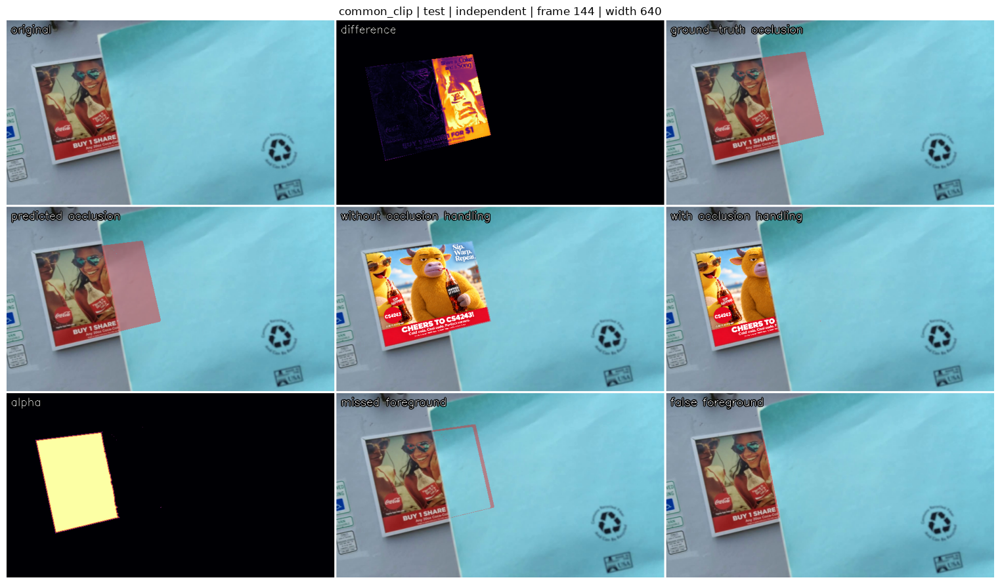

   144   scored   0.8689   0.9298    0.4301    0.0089     0.8751


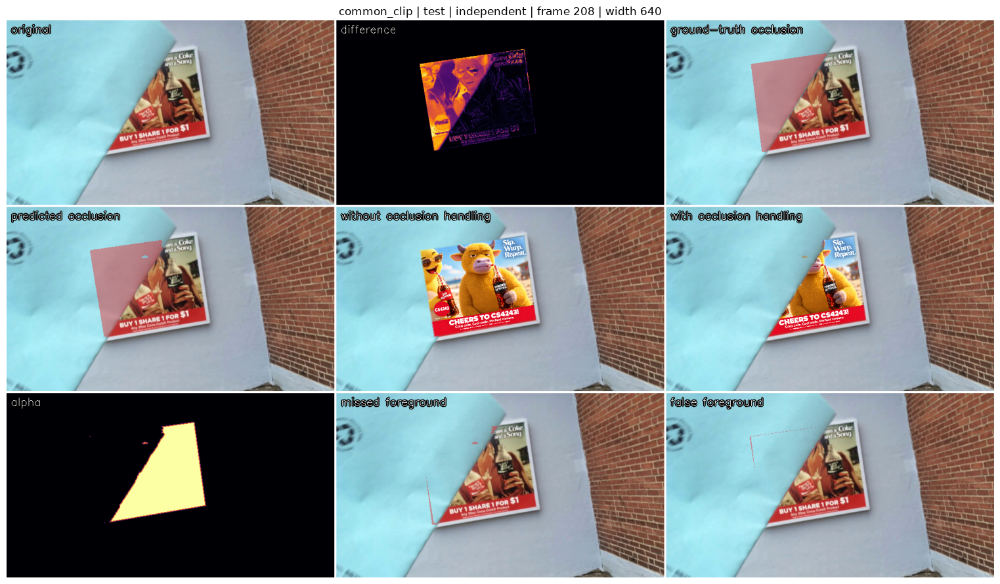

   208   scored   0.9409   0.9696    0.8780    0.0061     0.9668


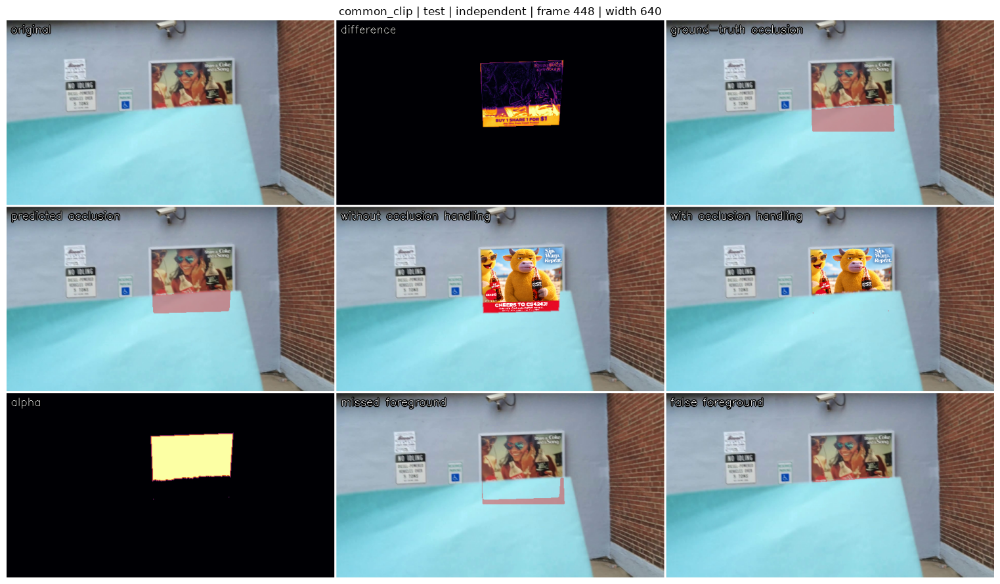

   448   scored   0.6892   0.8160    0.3944    0.0061     0.6981

Means and denominators (undefined metrics stay n/a):
{
  "expected": 3,
  "scored": 3,
  "hidden": 0,
  "missing": 0,
  "iou": {
    "mean": 0.8330022316933464,
    "n_scored": 3
  },
  "f1": {
    "mean": 0.9051387931312932,
    "n_scored": 3
  },
  "boundary_f1": {
    "mean": 0.5674922486386462,
    "n_scored": 3
  },
  "leakage": {
    "mean": 0.006998468161444532,
    "n_scored": 3
  },
  "baseline_iou": {
    "mean": 0.0,
    "n_scored": 3
  },
  "baseline_f1": {
    "mean": 0.0,
    "n_scored": 3
  },
  "baseline_boundary_f1": {
    "mean": 0.0,
    "n_scored": 3
  },
  "baseline_leakage": {
    "mean": 0.8466692296722015,
    "n_scored": 3
  }
}


In [4]:
# [AI-CODE] Held-out test evaluation: no settings are changed here.
assert_frozen()
masks_test = data.load_gt_masks("test", width=width)
assert len(masks_test) == 3 and not (set(masks_val) & set(masks_test))
mask_frames.update(read_mask_frames(masks_test))
rows = []
print(f"common_clip | test | independent | width {width}")
print(f"{'frame':>6} {'status':>8} {'IoU':>8} {'F1':>8} {'boundary':>9} {'leakage':>9} {'base leak':>10}")
for i in sorted(masks_test):
    status = "missing" if i not in mask_frames else "scored"
    if status == "scored":
        H, _, _, _, diag = localise_board(reference, mask_frames[i], config.localisation)
        homs[i] = H if H is not None and diag["status"] else None
        localisation_diagnostics[i] = diag
        if homs[i] is None:
            status = "hidden"
    if status != "scored":
        row = {"clip": "common_clip", "subset": "test", "variant": "independent",
               "frame": int(i), "status": status, "processing_width": width}
        row.update({k: float("nan") for k in (*METRIC_KEYS, *("baseline_" + k for k in METRIC_KEYS))})
    else:
        row = evaluate_mask_frame(i, masks_test[i], "test")
    rows.append(row)
    print(f"{i:6d} {status:>8} {fmt(row['iou']):>8} {fmt(row['f1']):>8} "
          f"{fmt(row['boundary_f1']):>9} {fmt(row['leakage']):>9} {fmt(row['baseline_leakage']):>10}")
test_summary = summarise_rows(rows, len(masks_test))
print("\nMeans and denominators (undefined metrics stay n/a):")
print(json.dumps(test_summary, indent=2))
(EVIDENCE / "common_test_metrics.json").write_text(json.dumps({
    "clip": "common_clip", "subset": "test", "variant": "independent",
    "processing_width": width, "rows": rows, "summary": test_summary,
    "frozen_occlusion": asdict(config.occlusion)}, indent=2), encoding="utf-8")
fieldnames = list(dict.fromkeys(key for row in rows for key in row))
sp.write_csv(EVIDENCE / "common_test_metrics.csv", rows, fieldnames)
assert_frozen()

## 5. What the thresholds and the hysteresis step do (**Question 4**)
These are explanations of the frozen configuration, using validation masks only. Each ablation changes one
factor. Compare higher strong, larger minimum area, weak=strong (no hysteresis), and opening radius 0 against the
frozen opening. Record mask size, IoU and leakage. These plots must not be used to revise settings after reading
test/stress results. [AI-DESIGN]

A nominal opening diameter is `2 * open_radius + 1` pixels: narrow structures are vulnerable to erosion, with
survival also depending on orientation/shape. Hysteresis can retain faint edges connected to strong seeds; it
cannot recover a component with no strong seed. Opening may remove that recovered thin structure. In Q4 use
the measured radius-0 versus frozen-radius results to describe the benefit/cost; do not claim a thinnest surviving
real occluder without inspecting its width. [AI-LANGUAGE]

frozen            : IoU 0.8971 (n=3), leakage 0.0136 (n=3); opening diameter 5 px
higher strong     : IoU 0.8971 (n=3), leakage 0.0136 (n=3); opening diameter 5 px
larger min_area   : IoU 0.8971 (n=3), leakage 0.0136 (n=3); opening diameter 5 px
no hysteresis     : IoU 0.6778 (n=3), leakage 0.1985 (n=3); opening diameter 5 px
no opening        : IoU 0.8863 (n=3), leakage 0.0134 (n=3); opening diameter 1 px


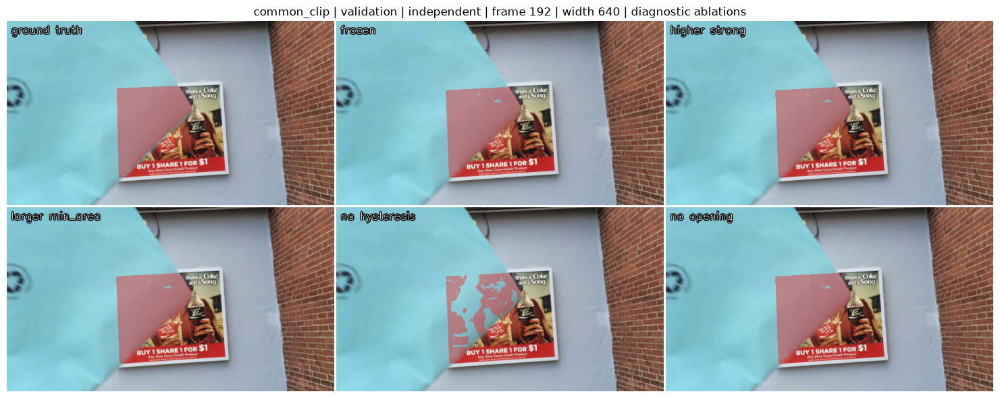

In [5]:
# [AI-CODE] Validation-only diagnostic ablations; leave config untouched.
assert_frozen()
ablations = {
    "frozen": config.occlusion,
    "higher strong": replace(config.occlusion, strong=min(1.0, config.occlusion.strong * 1.5)),
    "larger min_area": replace(config.occlusion, min_area=config.occlusion.min_area * 6),
    "no hysteresis": replace(config.occlusion, weak=config.occlusion.strong),
    "no opening": replace(config.occlusion, open_radius=0),
}
ablation_rows = []
i = sorted(masks_val)[1]
comparison_panels = []
for name, candidate in ablations.items():
    for frame_id in sorted(masks_val):
        frame = mask_frames[frame_id]
        Ha = artwork_to_frame(artwork, homs[frame_id], config.localisation)
        warped, cov = warp_artwork(artwork, Ha, frame.shape)
        mask, _, components = occlusion_mask(frame, homs[frame_id], reference, candidate)
        _, alpha = composite(frame, warped, cov, mask, config.composite)
        ablation_rows.append({"clip": "common_clip", "subset": "validation", "variant": "independent",
                              "frame": frame_id, "ablation": name, "settings": asdict(candidate),
                              "iou": metrics.mask_iou(mask, masks_val[frame_id]),
                              "leakage": metrics.leakage(alpha, masks_val[frame_id]),
                              "mask_pixels": int(mask.sum()), "components": int(len(components))})
        if frame_id == i:
            comparison_panels.append(viz.label(viz.overlay_mask(frame, mask), name))
    selected = [r for r in ablation_rows if r["ablation"] == name]
    iou, n_iou = finite_mean(r["iou"] for r in selected)
    leakage, n_leak = finite_mean(r["leakage"] for r in selected)
    print(f"{name:18s}: IoU {fmt(iou)} (n={n_iou}), leakage {fmt(leakage)} (n={n_leak}); "
          f"opening diameter {2 * candidate.open_radius + 1} px")
comparison_panels.insert(0, viz.label(viz.overlay_mask(mask_frames[i], masks_val[i]), "ground truth"))
fig = plt.figure(figsize=(16, 6))
plt.imshow(viz.montage(comparison_panels, cols=3))
plt.axis("off")
plt.title(f"common_clip | validation | independent | frame {i} | width {width} | diagnostic ablations")
fig.tight_layout()
fig.savefig(EVIDENCE / "validation_occlusion_ablations.png", dpi=150)
plt.show()
(EVIDENCE / "validation_ablations.json").write_text(json.dumps(ablation_rows, indent=2), encoding="utf-8")
assert_frozen()

## 6. EVALUATION-ONLY GT-FALLBACK — the combined and viewpoint clips with the frozen thresholds (REQUIRED)
The Stage 3 stress clips, `data.stress_clips(3)`. `manifests/diagnostic_masks.csv` lists the mask frames of the
**combined** clip (the blue card crosses the poster while the camera rotates) and of the **viewpoint** clip (three
strong-keystone frames with an *empty* mask: nothing is in front of the board). With the configuration frozen above:

* **combined**: mask IoU / F1 / leakage on the six mask frames against the no-occlusion baseline, as in section 4.
* **viewpoint**: the **false-occlusion fraction** = fraction of the (visible) board that the mask wrongly removes when
  nothing occludes it; the no-occlusion baseline is 0 % false occlusion by construction. Here the homography is always
  available (frozen or GT-fallback), so the overlay is present on every mask frame and the number is a mean over all
  three mask frames. `overlaylab.evaluate` estimates an output-pixel-change proxy on a *finished video*, only on mask frames where
  it detects the artwork in the output: frames where the overlay is absent (hidden by the monitor, tracker lost) are
  listed as `overlay_absent_frames` and excluded, and the printed line says how many frames the mean is based on. The proxy also includes feathering, resampling and similar artwork colours, so it need not equal the direct mask fraction. Always
  quote the frame count with the number. The full-resolution Stage 3 table comes from `python -m overlaylab.report`.

The homography of each frame comes from your `localise_board` with the frozen configuration. When it fails or exceeds the frozen corner-error threshold on a mask frame
(the card covers most of the poster on some combined-clip frames), the cell falls back to the manifest corners through
`cv2.getPerspectiveTransform` **for the mask evaluation only** and labels the row `GT-fallback`; say so in the report and
never use that fallback anywhere else. **Question 4** asks why the viewpoint clip produces false occlusion under strong
perspective even when the homography is correct.

     clip frame           H    IoU     F1  leakage base leak false occ coverage
 combined   212 GT-fallback  0.961  0.980    0.001     0.974     0.013    0.945
 combined   216      frozen  0.975  0.988    0.001     0.978     0.008    0.940
 combined   220      frozen  0.967  0.983    0.003     0.968     0.003    0.967
 combined   304      frozen  0.873  0.932    0.000     0.923     0.018    0.922
 combined   306      frozen  0.889  0.941    0.000     0.887     0.008    0.926
 combined   314      frozen  0.836  0.911    0.000     0.861     0.013    0.926


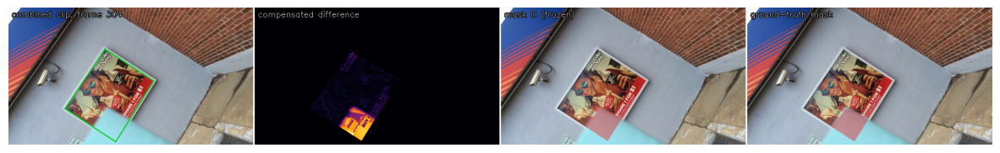

viewpoint   128      frozen    n/a    n/a    n/a    n/a     0.000    0.959
viewpoint   224      frozen    n/a    n/a    n/a    n/a     0.045    0.892
viewpoint   288 GT-fallback    n/a    n/a    n/a    n/a     0.027    0.901


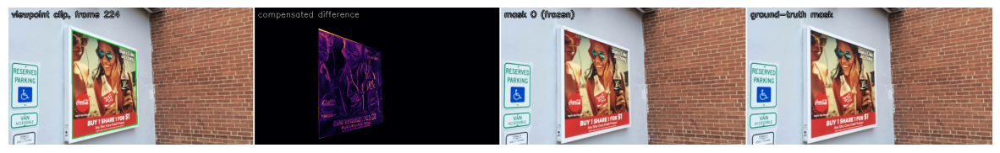

combined clip (coke_unconstrained): mean IoU 0.917  mean leakage 0.001 (baseline 0.932)  false occlusion 0.010 over 6 frames  coverage 0.938 over 6 frames  GT-fallback rows 1/6
viewpoint clip (coke_perspective): mean IoU nan  mean leakage nan (baseline nan)  false occlusion 0.024 over 3 frames  coverage 0.917 over 3 frames  GT-fallback rows 1/3


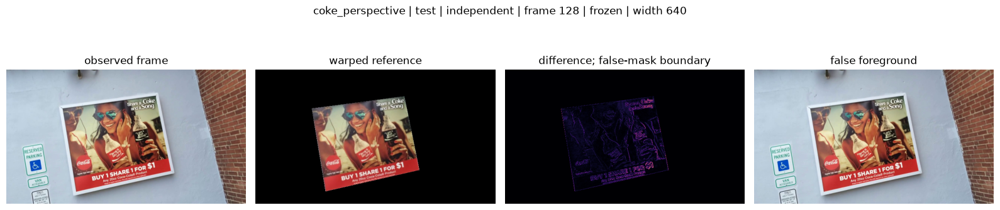

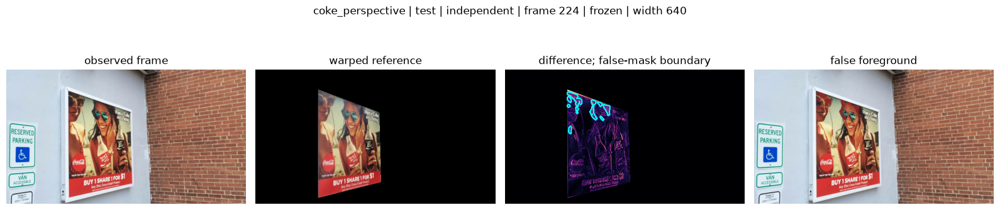

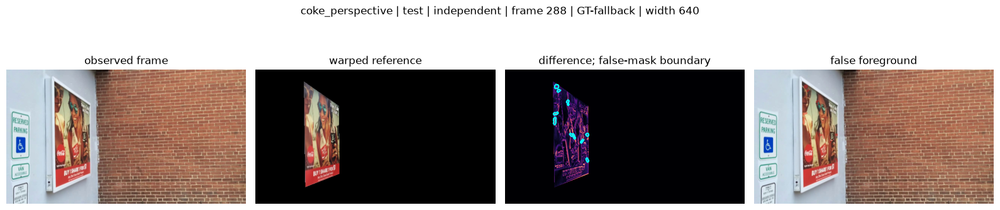

Settings unchanged. Use difference/false-mask panels as evidence for Q4; do not retune from them.


In [6]:
# [AI-CODE] Verify frozen configuration before the supplied stress analysis.
assert_frozen()
ref_rect = sp.rect_corners(reference.shape[1], reference.shape[0]).astype(np.float32)
print(f"{'clip':>9s} {'frame':>5s} {'H':>11s} {'IoU':>6s} {'F1':>6s} {'leakage':>8s} {'base leak':>9s} {'false occ':>9s} {'coverage':>8s}")
stress_rows = {}
for level, cid in [(name, data.stress_clips(3)[name]) for name in ("combined", "viewpoint")]:
    video, _ = data.clip_paths(cid)
    gm = {f: (sp.resize_width(m.astype(np.uint8) * 255, width) > 127) for f, m in data.load_diagnostic_masks(cid).items()}
    gc = data.load_diagnostic_mask_corners(cid, scale=factor)
    fr = {i: f for i, f in sp.iter_video(video, step=1, width=width, start=min(gm), stop=max(gm) + 1) if i in gm}
    for f in sorted(fr):
        H, corners, pairs, inliers, diag = localise_board(reference, fr[f], config.localisation)
        source = "frozen"
        if H is None or not diag["status"] or metrics.corner_error(corners, gc[f]) > config.localisation.success_threshold:
            H = cv2.getPerspectiveTransform(ref_rect, gc[f].astype(np.float32)).astype(np.float64); source = "GT-fallback"
        m, dmap, comp = occlusion_mask(fr[f], H, reference, config.occlusion)
        Ha = artwork_to_frame(artwork, H, config.localisation); warped, cov = warp_artwork(artwork, Ha, fr[f].shape)
        out, alpha = composite(fr[f], warped, cov, m, config.composite)
        base, alpha_base = composite(fr[f], warped, cov, np.zeros_like(m), config.composite)
        board = sp.quad_mask(m.shape, gc[f]); visible = board & ~gm[f]
        row = {"clip": level, "frame": f, "H": source,
               "iou": metrics.mask_iou(m, gm[f]) if gm[f].any() else float("nan"), "f1": metrics.mask_f1(m, gm[f]) if gm[f].any() else float("nan"),
               "leakage": metrics.leakage(alpha, gm[f]), "baseline_leakage": metrics.leakage(alpha_base, gm[f]),
               "false_occlusion": float((m & visible).sum() / max(visible.sum(), 1)), "coverage_visible": float(((alpha > 0.5) & visible).sum() / max(visible.sum(), 1))}
        stress_rows[(level, f)] = row
        g = lambda v, fmt="{:6.3f}": (fmt.format(v) if np.isfinite(v) else "   n/a")
        print(f"{level:>9s} {f:5d} {source:>11s} {g(row['iou'])} {g(row['f1'])} {g(row['leakage'], '{:8.3f}')} {g(row['baseline_leakage'], '{:9.3f}')} {row['false_occlusion']:9.3f} {row['coverage_visible']:8.3f}")
    show = sorted(fr)[len(fr) // 2]; H_show = stress_rows[(level, show)]
    m, dmap, _ = occlusion_mask(fr[show], cv2.getPerspectiveTransform(ref_rect, gc[show].astype(np.float32)).astype(np.float64) if H_show["H"] == "GT-fallback" else localise_board(reference, fr[show], config.localisation)[0], reference, config.occlusion)
    plt.figure(figsize=(15, 4)); plt.imshow(viz.montage([viz.label(viz.draw_quad(fr[show], gc[show]), f"{level} clip, frame {show}"), viz.label(viz.heatmap(dmap, 0.6), "compensated difference"), viz.label(viz.overlay_mask(fr[show], m), f"mask O ({H_show['H']})"), viz.label(viz.overlay_mask(fr[show], gm[show]), "ground-truth mask")], cols=4)); plt.axis("off"); plt.show()
nm = lambda xs: float(np.nanmean(xs)) if np.any(np.isfinite(xs)) else float("nan")   # nan when every entry is nan (the viewpoint clip has no foreground)
for level in ("combined", "viewpoint"):
    rows_l = [r for (lv, _), r in stress_rows.items() if lv == level]
    print(f"{level} clip ({data.stress_clips(3)[level]}): mean IoU {nm([r['iou'] for r in rows_l]):.3f}  mean leakage {nm([r['leakage'] for r in rows_l]):.3f} "
          f"(baseline {nm([r['baseline_leakage'] for r in rows_l]):.3f})  false occlusion {np.mean([r['false_occlusion'] for r in rows_l]):.3f} over {len(rows_l)} frames  coverage {np.mean([r['coverage_visible'] for r in rows_l]):.3f} over {len(rows_l)} frames  "
          f"GT-fallback rows {sum(r['H'] == 'GT-fallback' for r in rows_l)}/{len(rows_l)}")

# [AI-CODE] Viewpoint evidence: false mask locations relative to the compensated difference.
# Inspection cannot establish whether a residual is a highlight or resampling artefact by itself.
cid = data.stress_clips(3)["viewpoint"]
video, _ = data.clip_paths(cid)
view_masks = data.load_diagnostic_masks(cid)
view_corners = data.load_diagnostic_mask_corners(cid, scale=factor)
view_frames = {f: image for f, image in sp.iter_video(
    video, width=width, start=min(view_masks), stop=max(view_masks) + 1) if f in view_masks}
view_diagnostics = []
for frame_id in sorted(view_frames):
    frame = view_frames[frame_id]
    H, corners, _, _, diag = localise_board(reference, frame, config.localisation)
    source = stress_rows[("viewpoint", frame_id)]["H"]
    if source == "GT-fallback":
        # Permitted here ONLY: evaluation of masks with explicit GT-fallback label.
        H = cv2.getPerspectiveTransform(ref_rect, view_corners[frame_id].astype(np.float32)).astype(np.float64)
    warped_ref, cov = warp_artwork(reference, H, frame.shape)
    difference, (gain, offset) = compensated_difference(frame, warped_ref, cov, config.occlusion)
    mask, _, components = occlusion_mask(frame, H, reference, config.occlusion)
    board = sp.quad_mask(mask.shape, view_corners[frame_id])
    false_mask = mask & board  # viewpoint ground truth contains no foreground
    support = board & cov
    weak_fraction = float((support & (difference > config.occlusion.weak)).sum() / max(support.sum(), 1))
    edge_lengths = np.linalg.norm(np.roll(view_corners[frame_id], -1, axis=0) - view_corners[frame_id], axis=1)
    keystone = float(max(edge_lengths[0] / max(edge_lengths[2], 1e-9),
                         edge_lengths[2] / max(edge_lengths[0], 1e-9),
                         edge_lengths[1] / max(edge_lengths[3], 1e-9),
                         edge_lengths[3] / max(edge_lengths[1], 1e-9)))
    view_diagnostics.append({"clip": cid, "subset": "test", "variant": "independent",
                             "frame": frame_id, "homography_source": source,
                             "gain": gain, "offset": offset, "keystone_edge_ratio": keystone,
                             "fraction_above_weak_in_covered_board": weak_fraction,
                             "false_occlusion": float(false_mask.sum() / max(board.sum(), 1)),
                             "component_stats": components.tolist()})
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(frame); axes[0].set_title("observed frame")
    axes[1].imshow(warped_ref); axes[1].set_title("warped reference")
    axes[2].imshow(difference, cmap="magma", vmin=0, vmax=0.6)
    if false_mask.any():
        axes[2].contour(false_mask.astype(float), levels=[0.5], colors="cyan")
    axes[2].set_title("difference; false-mask boundary")
    axes[3].imshow(viz.overlay_mask(frame, false_mask)); axes[3].set_title("false foreground")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"{cid} | test | independent | frame {frame_id} | {source} | width {width}")
    fig.tight_layout()
    fig.savefig(EVIDENCE / f"viewpoint_false_occlusion_{frame_id:06d}.png", dpi=150)
    plt.show()
(EVIDENCE / "stress_mask_diagnostics.json").write_text(json.dumps({
    "processing_width": width,
    "evaluation_only": True,
    "warning": "Rows labelled GT-fallback are NOT pipeline predictions and cannot enter final stress tables.",
    "rows": list(stress_rows.values()), "viewpoint_diagnostics": view_diagnostics,
}, indent=2), encoding="utf-8")
assert_frozen()
print("Settings unchanged. Use difference/false-mask panels as evidence for Q4; do not retune from them.")


## 7. Optional ablation — `mode="colour"`
A colour-histogram back-projection of the board appearance as an alternative occlusion signal.

In [7]:
# [AI-CODE] Optional appearance-mode check on a validation frame only.
assert_frozen()
i = sorted(masks_val)[0]
try:
    m_col, d_col, _ = occlusion_mask(mask_frames[i], homs[i], reference,
                                    replace(config.occlusion, mode="colour"))
    print("common_clip | validation | independent | optional colour mode | frame", i,
          "| IoU:", fmt(metrics.mask_iou(m_col, masks_val[i])))
except NotImplementedError:
    print("Colour mode not implemented (optional); required difference results are unchanged.")
assert_frozen()

Colour mode not implemented (optional); required difference results are unchanged.


## Reflection prompts
1. Which pixels of the card are missed, and what in the difference map explains it (hint: compare the card's colour with the poster's sky)?
2. Where does the mask leak outside the card, and is that a homography error or a difference-threshold error?
3. The card is a uniform, strongly coloured occluder. Which occluder in your own clip (an arm, a bag, a ball) would be harder, and why?
4. What would a shadow cast on the poster do to the mask, and how would you tell it apart from an occluder?
5. On the viewpoint clip the homography is correct and nothing occludes the board, yet pixels are masked. Which assumption of the differencing fails under strong perspective (**Question 4**)?

## Evidence to use in the report
After running from a fresh kernel, inspect `student_files/notebook3/`: validation search/log and configuration,
per-frame validation/test metrics, per-metric denominators, nine-panel common-clip comparisons, validation-only
ablations and the labelled stress diagnostics. These are notebook-width evidence, not final full-resolution
stress tables. All images/numbers identify clip, subset and independent variant. [AI-CODE]

For Q4 discuss the measurements actually produced: which card pixels are missed; components outside the card;
changes from higher strong/larger area; hysteresis versus opening; and where the viewpoint difference remains
high despite no foreground. A homography aligns geometry but a single global gain/offset assumes a shared
photometric relationship: viewpoint-dependent reflections and different spatial sampling/blur need not obey it.
An occluder resembling the board can remain ambiguous; a shadow or highlight can appear as foreground; an
occluder that stops still differs from the clean reference, so stopping alone does not make it disappear from this
reference-based signal. Do not attribute a particular image residual to a cause without inspecting its panels.
[AI-LANGUAGE]

No numerical findings are pre-filled. These cells have not been executed as part of this edit. Codex supplied the
code and explanatory text; include the relevant cells and generated artefacts in the AI-use disclosure. Add
`[HUMAN-CHECK]` only after independent verification. [AI-CODE] [AI-LANGUAGE]